<a href="https://colab.research.google.com/github/jonathan-ha1/Econ_3916_Midterm/blob/main/midterm_starter_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [23]:
SOURCE_URL = "https://www.basketball-reference.com/contracts/players.html ; https://www.basketball-reference.com/leagues/NBA_2026_advanced.html"       # the page or file you downloaded from
DOWNLOAD_DATE = "2026-11-04"    # YYYY-MM-DD
FILE_NAME = "data/NBA_salaries.csv ; data/NBA_Stats.csv"        # the file as saved in your repository's data/ folder

**Who collected it, for what purpose, what is missing and why?**

*Your notes here.*

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [24]:
salaries = pd.read_csv("NBA_salaries.csv")
salaries = salaries.dropna(subset=["player_id"])
salaries = salaries[["player_id", "Player", "Tm", "Salary"]]
print(salaries.shape)
salaries.head()

(455, 4)


,player_id,Player,Tm,Salary
0,curryst01,Stephen Curry,GSW,62587158
1,jokicni01,Nikola Jokić,DEN,59033114
2,tatumja01,Jayson Tatum,BOS,58456566
3,davisan02,Anthony Davis,WAS,58456566
4,antetgi01,Giannis Antetokounmpo,MIA,58456566


In [25]:
stats = pd.read_csv("NBA_Stats.csv")
print(stats.shape)
stats.head()

(582, 30)


,Rk,Player,Age,Team,Pos,G,GS,MP,PER,TS%,...,OWS,DWS,WS,WS/48,OBPM,DBPM,BPM,VORP,Awards,player_id
0,1,Amen Thompson,23,HOU,PG,79,79,2953,18.9,0.594,...,6.5,3.8,10.3,0.167,1.6,1.0,2.6,3.4,DPOY-8,thompam01
1,2,Kevin Durant,37,HOU,SF,78,78,2840,21.1,0.641,...,7.5,3.2,10.7,0.180,4.4,0.1,4.5,4.7,CPOY-9ASNBA2,duranke01
2,3,Desmond Bane,27,ORL,SG,82,82,2756,16.9,0.607,...,4.8,2.6,7.4,0.129,1.6,-0.2,1.4,2.3,NaN,banede01
3,4,Toumani Camara,25,POR,PF,82,82,2731,11.3,0.578,...,2.1,2.7,4.8,0.084,-1.0,0.0,-1.0,0.7,NaN,camarto01
4,5,Jabari Smith Jr.,22,HOU,PF,77,77,2705,13.5,0.570,...,3.4,3.3,6.6,0.118,-0.5,-0.2,-0.7,0.9,NaN,smithja05


In [26]:
df = salaries.merge(stats[["player_id", "Age", "Pos", "MP", "BPM"]], on="player_id", how="inner")
n_merged = len(df)
print(df.shape)
df.head()

(397, 8)


,player_id,Player,Tm,Salary,Age,Pos,MP,BPM
0,curryst01,Stephen Curry,GSW,62587158,37,PG,1329,5.4
1,jokicni01,Nikola Jokić,DEN,59033114,30,C,2265,14.2
2,tatumja01,Jayson Tatum,BOS,58456566,27,PF,522,4.8
3,davisan02,Anthony Davis,WAS,58456566,32,PF,626,2.4
4,antetgi01,Giannis Antetokounmpo,MIA,58456566,31,PF,1039,9.5


In [27]:
df = df[df["MP"] >= 500]
df["log_salary"] = np.log(df["Salary"])
df["age_sq"] = df["Age"] ** 2
df["PG"] = (df["Pos"] == "PG").astype(int)
df["SG"] = (df["Pos"] == "SG").astype(int)
df["SF"] = (df["Pos"] == "SF").astype(int)
df["PF"] = (df["Pos"] == "PF").astype(int)
print(df.shape)
df.head()

(345, 14)


,player_id,Player,Tm,Salary,Age,Pos,MP,BPM,log_salary,age_sq,PG,SG,SF,PF
0,curryst01,Stephen Curry,GSW,62587158,37,PG,1329,5.4,17.952071,1369,1,0,0,0
1,jokicni01,Nikola Jokić,DEN,59033114,30,C,2265,14.2,17.893609,900,0,0,0,0
2,tatumja01,Jayson Tatum,BOS,58456566,27,PF,522,4.8,17.883795,729,0,0,0,1
3,davisan02,Anthony Davis,WAS,58456566,32,PF,626,2.4,17.883795,1024,0,0,0,1
4,antetgi01,Giannis Antetokounmpo,MIA,58456566,31,PF,1039,9.5,17.883795,961,0,0,0,1


In [28]:
summary = df[["Salary", "log_salary", "BPM", "Age", "MP"]].describe().round(2)
summary = summary.rename(columns={"Salary": "Salary 2026-27 ($)", "log_salary": "Log salary", "BPM": "BPM 2025-26", "Age": "Age (years)", "MP": "Minutes 2025-26"})
print(summary.to_string())

       Salary 2026-27 ($)  Log salary  BPM 2025-26  Age (years)  Minutes 2025-26
count              345.00      345.00       345.00       345.00           345.00
mean          15134022.23       16.05        -0.08        25.98          1520.12
std           15099476.95        1.00         2.91         4.23           572.94
min            2055000.00       14.54        -7.30        19.00           500.00
25%            3815861.00       15.15        -2.00        23.00          1095.00
50%            9160715.00       16.03        -0.40        25.00          1455.00
75%           20194392.00       16.82         1.70        28.00          1953.00
max           62587158.00       17.95        14.20        41.00          2953.00


In [29]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "player"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "log_salary"     # your dependent variable's column name
MAIN_X = "BPM"      # your main explanatory variable's column name
CONTROLS = ["Age", "age_sq", "PG", "SG", "SF", "PF"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 345   Columns: 14   One row is: player

Missing values per column:
log_salary    0
BPM           0
Age           0
age_sq        0
PG            0
SG            0
SF            0
PF            0

Skew of log_salary: 0.17 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

---------------------
1. My controls are age, age squared, and position, and BPM doesn’t affect any of these, since a player’s age and position don’t depend on how efficiently he played, so none of them sit on the path from BPM to salary. Minutes played is the exception, because better players get more playing time, which means BPM affects minutes and puts minutes on the path from BPM to salary. I leave minutes out of my main model and run a second version with it included, so the main model shows the overall relationship between BPM and salary, while the version with minutes shows the relationship for players who played about the same amount.
2. Salaries are all in US dollars for one season, and all the stats come from the same league and source, so the units match. The years are different on purpose, with salary from 2026-27 and stats from 2025-26, because teams base salaries on how players already performed, so this year’s salary couldn’t have caused last year’s BPM.
3. My question isn’t about a policy, so there;s no need for a before period.

***Among NBA players in 2026-27, how is a player’s efficiency last season (2025-26 Box Plus/Minus) related to his salary, controlling for age and position?***

Why it matters: Front offices have to decide how much to pay players, and players and agents negotiate based on what they think they’re worth, so this shows how much the league actually pays for how well someone plays.

Data: Both files come from Basketball-Reference, a site run by Sports Reference that collects NBA stats and publicly reported contract info for fans, media, and analysts. The salaries are what each player is set to make in 2026-27 based on his contract, not what he’s actually been paid, so they reflect what was agreed when he signed. BPM isn’t something you can directly observe, since it’s an estimate built from box score stats and team results, which makes it its own measurement choice.

What’s missing? After merging, there are no missing values in any variable, but 58 players with a 2026-27 salary have no 2025-26 stats, mostly rookies and guys who didn’t play last season. I also dropped 52 players who played under 500 minutes, since BPM isn’t reliable for players who barely played. This is considered as MNAR, because players usually miss a season or barely play due to injuries or poor performance, which is tied to the BPM they would have had. As a result, my sample of 345 leans toward healthy, established players, so my results are about how the league pays proven players, not every player.

Summary table: The average salary is 15.1 million dollars, but the median is only 9.2 million dollars, so salary is really right-skewed. A few stars make over 50 million dollars, with the highest salary in the sample at 62.6 million dollars, while a lot of players are close to the minimum. Raw salary has a skew of about 1.39, so I use log salary instead, which brings it down to 0.17. Average BPM is about 0, which makes sense since it’s measured against a league-average player, and it ranges from -7.3 to 14.2. The typical player is 25 and played about 1,450 minutes.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

Skew of salary: 1.39
Skew of log salary: 0.17


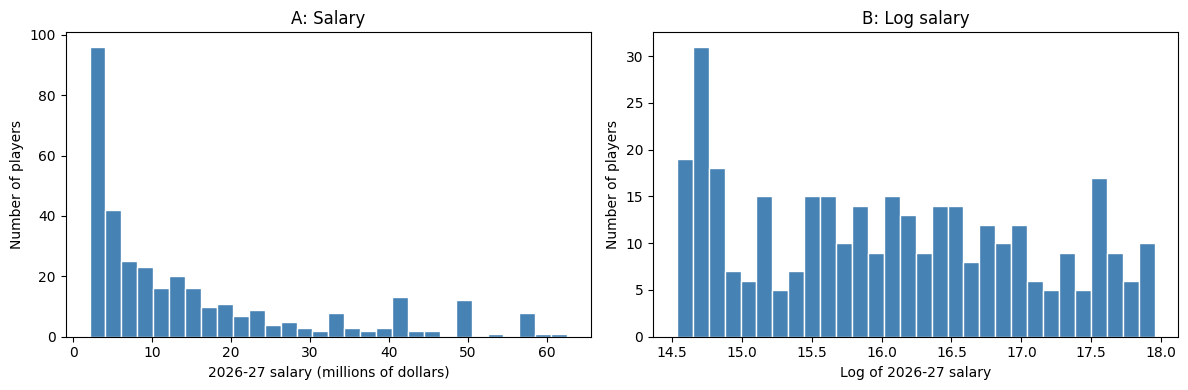

In [30]:
print(f"Skew of salary: {df['Salary'].skew():.2f}")
print(f"Skew of log salary: {df['log_salary'].skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Salary"] / 1_000_000, bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("A: Salary")
axes[0].set_xlabel("2026-27 salary (millions of dollars)")
axes[0].set_ylabel("Number of players")
axes[1].hist(df["log_salary"], bins=30, color="steelblue", edgecolor="white")
axes[1].set_title("B: Log salary")
axes[1].set_xlabel("Log of 2026-27 salary")
axes[1].set_ylabel("Number of players")
plt.tight_layout()
plt.show()

Correlation between BPM and log salary: 0.50


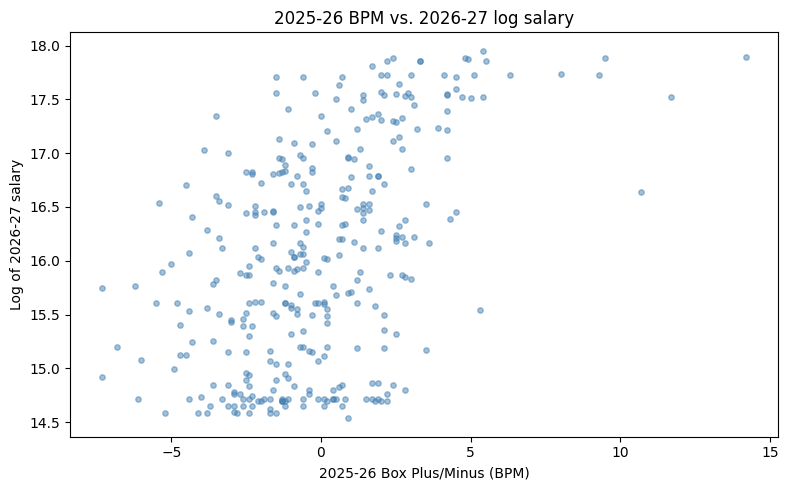

In [31]:
r = np.corrcoef(df["BPM"], df["log_salary"])[0, 1]
print(f"Correlation between BPM and log salary: {r:.2f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["BPM"], df["log_salary"], s=15, alpha=0.5, color="steelblue")
ax.set_title("2025-26 BPM vs. 2026-27 log salary")
ax.set_xlabel("2025-26 Box Plus/Minus (BPM)")
ax.set_ylabel("Log of 2026-27 salary")
plt.tight_layout()
plt.show()

Figure 1: Salary is very uneven, since about half of players make under 9.2 million dollars while the highest-paid player makes 62.6 million dollars, which gives raw salary a skew of 1.39 (Panel A). Using the log brings the skew down to 0.17 and spreads players out more evenly (Panel B), which is why the model uses log salary, but there’s still a spike on the far left from players making the league minimum, since their pay is set by league rules and not by how well they played.

Figure 2: Players with a higher BPM last season tend to earn more this season, with a correlation of 0.50 between BPM and log salary, but BPM is far from the whole story. Almost every player with a BPM above 5 earns much more than the league average, while at any BPM below that, salaries range from the minimum to over 40 million dollars, and the flat row of points along the bottom shows players stuck at the minimum across a wide range of BPM. This suggests that things like age and contract type also matter, which is why the regression in Section 3 controls for age and position.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [32]:
m1 = smf.ols("log_salary ~ BPM + Age + age_sq + PG + SG + SF + PF", data=df).fit()
m2 = smf.ols("log_salary ~ BPM + Age + age_sq + PG + SG + SF + PF + MP", data=df).fit()

def reg_table(model):
    """Print a model's coefficients and standard errors, with N and R-squared."""
    table = pd.DataFrame({"Coefficient": model.params, "Std. error": model.bse}).round(4)
    print(table.to_string())
    print(f"N = {int(model.nobs)}   R-squared = {model.rsquared:.3f}")

print("Model 1: without minutes (main model)")
reg_table(m1)
print("\nModel 2: with minutes (robustness check)")
reg_table(m2)

Model 1: without minutes (main model)
           Coefficient  Std. error
Intercept      10.6900      1.4842
BPM             0.1574      0.0169
Age             0.3485      0.1084
age_sq         -0.0056      0.0020
PG              0.2003      0.1547
SG              0.2220      0.1447
SF              0.2771      0.1526
PF              0.3568      0.1491
N = 345   R-squared = 0.303

Model 2: with minutes (robustness check)
           Coefficient  Std. error
Intercept       9.7518      1.4318
BPM             0.1177      0.0177
Age             0.3671      0.1039
age_sq         -0.0059      0.0019
PG              0.1109      0.1491
SG              0.1280      0.1396
SF              0.1548      0.1479
PF              0.3228      0.1430
MP              0.0005      0.0001
N = 345   R-squared = 0.362


In [33]:
lo, hi = m1.conf_int().loc["BPM"]
print(f"BPM coefficient: {m1.params['BPM']:.4f}, 95% CI {lo:.4f} to {hi:.4f}")
print(f"One more point of BPM: {np.exp(m1.params['BPM']) - 1:.1%} higher salary")
print(f"95% CI in percent: {np.exp(lo) - 1:.1%} to {np.exp(hi) - 1:.1%}")
print(f"With minutes (Model 2): {np.exp(m2.params['BPM']) - 1:.1%} higher salary")

peak = -m1.params["Age"] / (2 * m1.params["age_sq"])
print(f"Salary peaks at age {peak:.1f}")

BPM coefficient: 0.1574, 95% CI 0.1241 to 0.1906
One more point of BPM: 17.0% higher salary
95% CI in percent: 13.2% to 21.0%
With minutes (Model 2): 12.5% higher salary
Salary peaks at age 31.0


The table reports two OLS models of log 2026-27 salary, where Model 1 is my main model and Model 2 adds minutes as a robustness check. In both, age_sq is age squared, and PG, SG, SF, and PF are position dummies with centers as the comparison group.

BPM: The BPM coefficient in Model 1 is 0.1574, which means one more point of BPM last season is associated with about 17.0% higher salary this season, holding age and position fixed. This estimate is precise, with a standard error of 0.0169 and a 95% confidence interval of 13.2% to 21.0%, which shows that even the low end is a meaningful difference in pay.

Age: The age coefficient is 0.3485 and the age squared coefficient is -0.0056, so salary rises with age and then falls, peaking at age 31.0, which fits young players being on rookie contracts and older players taking smaller deals as they decline. Both are precise relative to their size, with standard errors of 0.1084 and 0.0020.

Controls: Age blocks a confounding path because it affects both how well players play and how much they get paid, and it could never be a bad control since BPM can’t change a player’s age. Age squared lets that age effect follow its rise-and-fall shape instead of a straight line. Position also blocks a confounding path, since bigger players tend to post higher BPMs through rebounds and blocks while teams may pay positions differently, and it would only be a bad control if playing well changed a player’s position, which it usually doesn’t.

Minutes: Minutes is left out of the main model because better players earn more playing time, so it sits on the path from BPM to salary. Adding it in Model 2 drops the BPM effect from 17.0% to 12.5%, which shows part of the relationship runs through playing time, so Model 1 measures the full association while Model 2 compares players who played the same minutes.

Fit: Model 1 has an R-squared of 0.303, so these variables explain about 30% of the variation in log salary, leaving a lot unexplained by things like contract timing and reputation.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

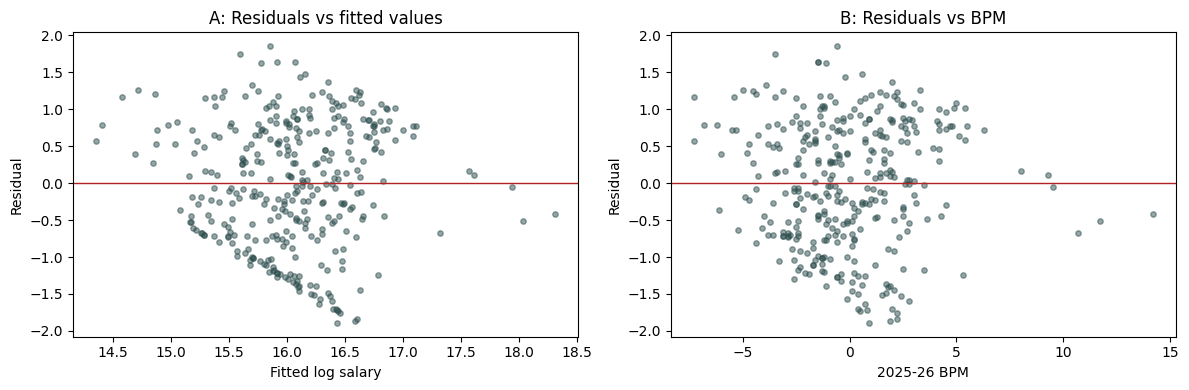

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(m1.fittedvalues, m1.resid, s=15, alpha=0.5, color="darkslategray")
axes[0].axhline(0, color="firebrick", lw=1)
axes[0].set_title("A: Residuals vs fitted values")
axes[0].set_xlabel("Fitted log salary")
axes[0].set_ylabel("Residual")
axes[1].scatter(df["BPM"], m1.resid, s=15, alpha=0.5, color="darkslategray")
axes[1].axhline(0, color="firebrick", lw=1)
axes[1].set_title("B: Residuals vs BPM")
axes[1].set_xlabel("2025-26 BPM")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

In [35]:
bp = het_breuschpagan(m1.resid, m1.model.exog)
print(f"Breusch-Pagan p = {bp[1]:.4f}")

m1_hc3 = smf.ols("log_salary ~ BPM + Age + age_sq + PG + SG + SF + PF", data=df).fit(cov_type="HC3", use_t=True)

print(f"\n{'term':<12}{'coef':>10}{'classical SE':>14}{'HC3 SE':>10}")
print("-" * 46)
for name in m1.params.index:
    print(f"{name:<12}{m1.params[name]:>10.4f}{m1.bse[name]:>14.4f}{m1_hc3.bse[name]:>10.4f}")

Breusch-Pagan p = 0.3545

term              coef  classical SE    HC3 SE
----------------------------------------------
Intercept      10.6900        1.4842    1.5481
BPM             0.1574        0.0169    0.0152
Age             0.3485        0.1084    0.1166
age_sq         -0.0056        0.0020    0.0022
PG              0.2003        0.1547    0.1604
SG              0.2220        0.1447    0.1481
SF              0.2771        0.1526    0.1479
PF              0.3568        0.1491    0.1512


In [36]:
X_vars = ["BPM", "Age", "age_sq", "PG", "SG", "SF", "PF"]
for x in X_vars:
    others = [c for c in X_vars if c != x]
    r2 = sm.OLS(df[x], sm.add_constant(df[others])).fit().rsquared
    print(f"{x:<8} VIF = {1 / (1 - r2):.2f}")

BPM      VIF = 1.16
Age      VIF = 100.73
age_sq   VIF = 99.91
PG       VIF = 1.66
SG       VIF = 1.90
SF       VIF = 1.71
PF       VIF = 1.75


In [37]:
cooks = m1.get_influence().cooks_distance[0]
worst = np.argsort(cooks)[::-1][:5]

top5 = df.iloc[worst][["Player", "Age", "BPM", "Salary"]].copy()
top5["cooks_d"] = cooks[worst]
print(top5.to_string())

trimmed = df.drop(df.index[worst])
refit = smf.ols("log_salary ~ BPM + Age + age_sq + PG + SG + SF + PF", data=trimmed).fit()
print(f"\nBPM with all 345 players:  {m1.params['BPM']:.4f}")
print(f"BPM without the top 5:     {refit.params['BPM']:.4f}")

             Player  Age  BPM    Salary   cooks_d
274    LeBron James   41  3.5   3876529  0.070453
348   DeMar DeRozan   36 -0.1   2449421  0.021551
352     Mike Conley   38 -1.3   2449421  0.021337
335  Nikola Vučević   35  1.5   2449421  0.015810
0     Stephen Curry   37  5.4  62587158  0.014642

BPM with all 345 players:  0.1574
BPM without the top 5:     0.1561


Residuals: In both residual plots, the points are scattered evenly above and below zero with no curve or fan shape, which suggests the model’s linear form fits reasonably well and that the errors don’t grow with fitted salary or with BPM. The one clear pattern is a straight diagonal edge along the bottom of the residuals vs fitted plot, which comes from players on the league minimum salary, since their salary can’t fall any lower, so as their predicted salary rises, their residual can only drop along that line. This is the same salary floor seen in Section 2, and it means the model overpredicts pay for some players whose salary is set by league rules rather than by performance.

Constant variance: The Breusch-Pagan test gives a p-value of 0.3545, which is far above 0.05, so there is no evidence that the spread of the residuals changes across players. Because of this, I keep the classical standard errors from Section 3, and the HC3 robust standard errors confirm this choice, since they barely differ, with the BPM standard error at 0.0169 classical and 0.0152 robust.

VIF: BPM has a VIF of 1.16 and the position dummies range from 1.66 to 1.90, so these variables are not strongly related to the other controls and their standard errors are barely inflated. Age and age squared have VIFs of about 100, but this is expected rather than a problem, since age squared is built directly from age, so the two move together almost perfectly. This inflates the standard errors on the two age terms individually, but it does not affect the BPM coefficient, which is the one my question is about.

Influence: The five most influential players by Cook’s distance are LeBron James, DeMar DeRozan, Mike Conley, Nikola Vučević, and Stephen Curry, and four of the five are older players on cheap contracts, with LeBron at age 41 earning about 3.9 million dollars despite a BPM of 3.5. These players stand out because the model expects older, productive players to be paid more, while near the end of their careers many take smaller deals. Dropping all five only moves the BPM coefficient from 0.1574 to 0.1561, so no small group of players is driving the main result.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

Threats to interpretation: For the BPM coefficient to be causal, BPM would need to be unrelated to every other determinant of salary once age and position are held fixed, and that is unlikely here. The main threat is contract timing, since many 2026-27 salaries come from contracts signed years earlier and reflect performance at signing rather than 2025-26 BPM. Unmeasured factors such as reputation, marketability, and injury history also likely affect both performance and pay, and rookie-scale contracts, which are set by the league’s pay scale rather than by performance, cannot be identified in this data. For these reasons, the estimate is best described as a conditional association: among established players with at least 500 minutes, a player whose BPM was one point higher last season earns about 17.0% more this season than a player of the same age and position.

Conclusion: How well a player performed last season is strongly related to how much he earns this season, with each additional point of BPM linked to about 17.0% higher pay. This result is precise and stable, since the 95% confidence interval runs from 13.2% to 21.0%, the Breusch-Pagan test found no sign that the model’s errors get bigger or smaller across players, and removing the five most influential players barely changes the estimate. However, the effect falls to 12.5% once minutes are held fixed, so it should not be read as the exact price teams pay for one point of BPM. With another month, I would match each player’s salary to his stats from the season his contract was signed, add more seasons of data with season dummies, and identify rookie-scale contracts so they could be looked at separately.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [38]:
print("Model 1: without minutes (main model)")
reg_table(m1)
print("\nModel 2: with minutes (robustness check)")
reg_table(m2)

Model 1: without minutes (main model)
           Coefficient  Std. error
Intercept      10.6900      1.4842
BPM             0.1574      0.0169
Age             0.3485      0.1084
age_sq         -0.0056      0.0020
PG              0.2003      0.1547
SG              0.2220      0.1447
SF              0.2771      0.1526
PF              0.3568      0.1491
N = 345   R-squared = 0.303

Model 2: with minutes (robustness check)
           Coefficient  Std. error
Intercept       9.7518      1.4318
BPM             0.1177      0.0177
Age             0.3671      0.1039
age_sq         -0.0059      0.0019
PG              0.1109      0.1491
SG              0.1280      0.1396
SF              0.1548      0.1479
PF              0.3228      0.1430
MP              0.0005      0.0001
N = 345   R-squared = 0.362


In [39]:
X_vars = ["BPM", "Age", "age_sq", "PG", "SG", "SF", "PF"]
vif = {}
for x in X_vars:
    others = [c for c in X_vars if c != x]
    r2 = sm.OLS(df[x], sm.add_constant(df[others])).fit().rsquared
    vif[x] = round(1 / (1 - r2), 2)
    print(f"{x:<8} VIF = {vif[x]:.2f}")

BPM      VIF = 1.16
Age      VIF = 100.73
age_sq   VIF = 99.91
PG       VIF = 1.66
SG       VIF = 1.90
SF       VIF = 1.71
PF       VIF = 1.75


## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [40]:
REPORT_NUMBERS = {
    "Section 1: players in salary file": len(salaries),
    "Section 1: salary players with no 2025-26 stats": len(salaries) - n_merged,
    "Section 1: players dropped for under 500 minutes": n_merged - len(df),
    "Section 1: rows in the final sample": len(df),
    "Section 1: mean salary (millions)": round(df["Salary"].mean() / 1_000_000, 1),
    "Section 1: median salary (millions)": round(df["Salary"].median() / 1_000_000, 1),
    "Section 1: max salary (millions)": round(df["Salary"].max() / 1_000_000, 1),
    "Section 1: skew of salary": round(df["Salary"].skew(), 2),
    "Section 1: skew of log salary": round(df["log_salary"].skew(), 2),
    "Section 1: mean BPM": round(df["BPM"].mean(), 2),
    "Section 1: min BPM": df["BPM"].min(),
    "Section 1: max BPM": df["BPM"].max(),
    "Section 1: median age": df["Age"].median(),
    "Section 1: median minutes": df["MP"].median(),
    "Section 2: correlation of BPM and log salary": round(r, 2),
    "Section 3: BPM coefficient (Model 1)": round(m1.params["BPM"], 4),
    "Section 3: BPM standard error (Model 1)": round(m1.bse["BPM"], 4),
    "Section 3: percent higher salary per BPM point": round(100 * (np.exp(m1.params["BPM"]) - 1), 1),
    "Section 3: 95% CI in percent, low": round(100 * (np.exp(lo) - 1), 1),
    "Section 3: 95% CI in percent, high": round(100 * (np.exp(hi) - 1), 1),
    "Section 3: percent per BPM point (Model 2)": round(100 * (np.exp(m2.params["BPM"]) - 1), 1),
    "Section 3: Age coefficient": round(m1.params["Age"], 4),
    "Section 3: Age standard error": round(m1.bse["Age"], 4),
    "Section 3: age_sq coefficient": round(m1.params["age_sq"], 4),
    "Section 3: age_sq standard error": round(m1.bse["age_sq"], 4),
    "Section 3: peak salary age": round(peak, 1),
    "Section 3: R-squared (Model 1)": round(m1.rsquared, 3),
    "Section 3: R-squared (Model 2)": round(m2.rsquared, 3),
    "Section 4: Breusch-Pagan p-value": round(bp[1], 4),
    "Section 4: BPM HC3 standard error": round(m1_hc3.bse["BPM"], 4),
    "Section 4: BPM coefficient without top 5 influential": round(refit.params["BPM"], 4),
    "Section 4: LeBron James salary (millions)": round(top5["Salary"].iloc[0] / 1_000_000, 1),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

for x in X_vars:
    print(f"Section 4: VIF for {x}: {vif[x]}")

Section 1: players in salary file: 455
Section 1: salary players with no 2025-26 stats: 58
Section 1: players dropped for under 500 minutes: 52
Section 1: rows in the final sample: 345
Section 1: mean salary (millions): 15.1
Section 1: median salary (millions): 9.2
Section 1: max salary (millions): 62.6
Section 1: skew of salary: 1.39
Section 1: skew of log salary: 0.17
Section 1: mean BPM: -0.08
Section 1: min BPM: -7.3
Section 1: max BPM: 14.2
Section 1: median age: 25.0
Section 1: median minutes: 1455.0
Section 2: correlation of BPM and log salary: 0.5
Section 3: BPM coefficient (Model 1): 0.1574
Section 3: BPM standard error (Model 1): 0.0169
Section 3: percent higher salary per BPM point: 17.0
Section 3: 95% CI in percent, low: 13.2
Section 3: 95% CI in percent, high: 21.0
Section 3: percent per BPM point (Model 2): 12.5
Section 3: Age coefficient: 0.3485
Section 3: Age standard error: 0.1084
Section 3: age_sq coefficient: -0.0056
Section 3: age_sq standard error: 0.002
Section 3:

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.